In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.ndimage import gaussian_filter
from scipy.io import loadmat
from pathlib import Path
from matplotlib.patches import Rectangle
import re
import os


if os.getcwd().endswith('scripts'):
    os.chdir('..')
os.getcwd()

Matplotlib is building the font cache; this may take a moment.


'/Users/benjy/Documents/PYTHON /DA3/DA3_VSDI_S1_G1_2026'

In [ ]:
current_dir = Path.cwd()
folder = current_dir.parent
data_folder = folder / 'data'

In [16]:
current_dir = Path('scripts/latency.py')
test = current_dir.resolve().parent.parent.parent
for i in test.iterdir():
    print(i)

/Users/benjy/Documents/PYTHON /DA3/DA3_VSDI_S1_G1_2026
/Users/benjy/Documents/PYTHON /DA3/data


In [ ]:
## load the condition
## condition is the order of the finger stimulations

condition_load = np.load(data_folder / 'New_list_conditions.npy')
condition = []

for i in condition_load[0::2]:
    cond = re.split('_', str(i))[0]
    condition.append(cond[-1])

condition = np.array(condition)

In [4]:
# parameters
sig = 1 ## for the gaussian filter

In [ ]:
## extract data from trials

Cortex = np.load(data_folder / 'Image_Cortex.npy')  
x = np.arange(1, 31, 1)

delta_f = []

for trial_num in x:
    stim = np.load(data_folder / f'Trial_{trial_num}_Stim.npy')
    control = np.load(data_folder / f'Trial_{trial_num}_Control.npy')

    df = (stim - control)/control
    delta_f.append(df)

delta_f = np.array(delta_f)

df_filtered = gaussian_filter(delta_f.copy(), sigma=(0, sig, sig, 0)) 
# df_test = gaussian_filter(delta_f.copy(), sigma=(0, sig, sig, sig))

In [7]:
cond1_index = np.where(condition == '1')[0]
cond2_index = np.where(condition == '2')[0]
cond3_index = np.where(condition == '3')[0]

In [123]:
cond1_ave = np.mean(df_filtered[cond1_index], axis=0)
cond2_ave = np.mean(df_filtered[cond2_index], axis=0)
cond3_ave = np.mean(df_filtered[cond3_index], axis=0)

### Extract baseline

In [114]:
baseline = df_filtered[:,:,:,:33]

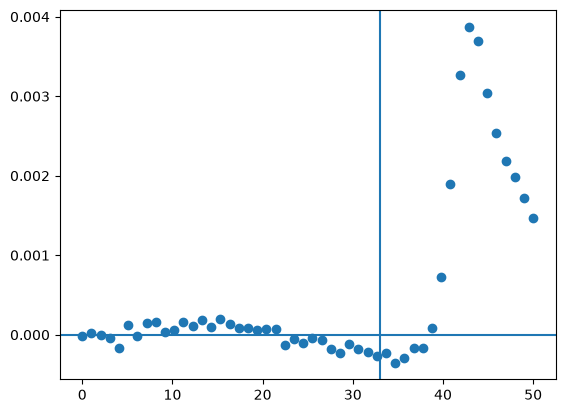

In [129]:
y = cond2_ave[50,50,:50]
pre_stim = cond2_ave[50,50,:33]

x = np.linspace(0, len(y), len(y))
plt.scatter(x, y)
plt.axvline(x=33)
plt.axhline(y=np.mean(pre_stim))

In [176]:
from scipy.stats import ttest_1samp, ttest_ind, ttest_rel, linregress


In [208]:
index = []
conds = [cond1_ave, cond2_ave, cond3_ave]

for cond in conds:
    p_value = []
    for i in range(20):
        stat, pvalue = ttest_1samp(cond[60,60,:33], cond[60,60,33+i])
        p_value.append(pvalue)
    p_value = np.array(p_value)
    index.append(p_value.argmax())

index

[np.int64(2), np.int64(3), np.int64(2)]

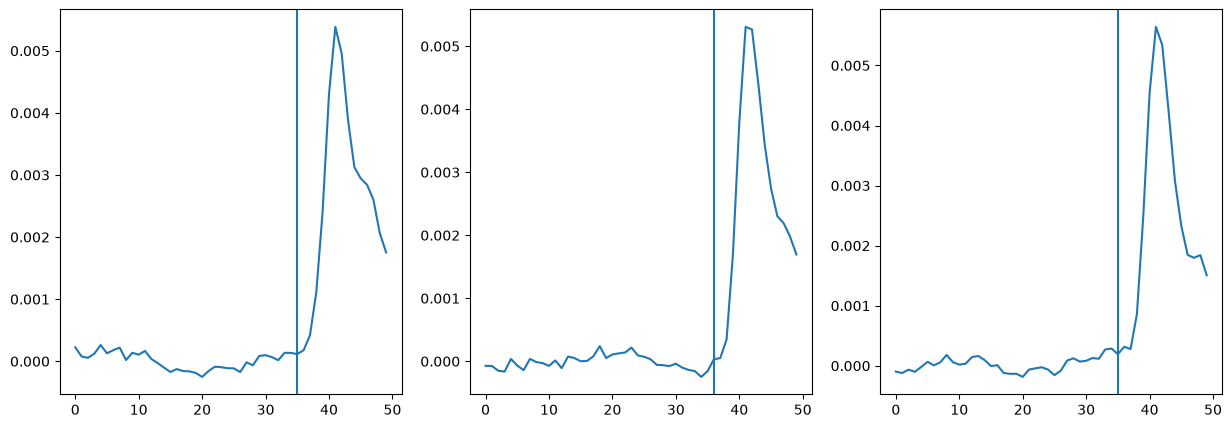

In [209]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))

ax[0].plot(cond1_ave[60,60,:50])
ax[0].axvline(33+index[0])

ax[1].plot(cond2_ave[60,60,:50])
ax[1].axvline(33+index[1])

ax[2].plot(cond3_ave[60,60,:50])
ax[2].axvline(33+index[2])

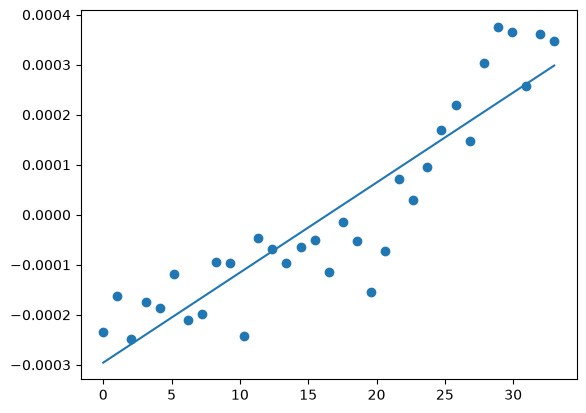

In [187]:
points = 33
x = np.linspace(0, points, points)
res = linregress(x, cond3_ave[50,50,:points])
plt.plot(x, res.slope*x + res.intercept)
plt.scatter(x, cond3_ave[50,50,:points])

In [179]:
linregress(np.linspace(0, points, points), cond3_ave[50,50,:points])

LinregressResult(slope=np.float64(5.70547875639664e-05), intercept=np.float64(-0.0008224679116135707), rvalue=np.float64(0.7322068850248594), pvalue=np.float64(1.5162706684257482e-09), stderr=np.float64(7.660149566460433e-06), intercept_stderr=np.float64(0.00022225481879707167))